<a href="https://colab.research.google.com/github/cintiapinho/Aulas_FATEC_PLN/blob/main/Materiais/aula%207_Avaliac%C3%A3o%20de%20modelos%20e%20Aprendizado%20n%C3%A3o%20supervisionado%20com%20PLN/Avaliacao_de_Modelos_supervisionados_e_Como_usar_modelos_n%C3%A3o_supervisionados_com_PLN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sessão 07 — Avaliação de Modelos Supervisionados e Aprendizado Não Supervisionado

**Processamento de Linguagem Natural**

Notebook da aula: tem todas as explicações, imagens e códigos. Dá para acompanhar a aula inteira por aqui, sem slide.

Nas Sessões 05-06 treinamos classificadores com **duas** classes (ofensivo ou não, recomenda ou não) e olhamos principalmente a acurácia. Hoje vamos mais longe, em duas partes:

**Parte 1 — Avaliar um modelo supervisionado de verdade.**
- Um problema com **quatro** classes: alegria, raiva, medo e tristeza.
- Quatro algoritmos lado a lado: SGDClassifier, Árvore de Decisão, Gradient Boosting e SVM.
- A **matriz de confusão** de cada um e o `classification_report` explicado linha por linha: precisão, recall, F1, *support*, média macro e ponderada.
- Como não se enganar com um número só: validação cruzada, CountVectorizer × TF-IDF, busca de hiperparâmetros e limiar de decisão.

**Parte 2 — E quando não existe rótulo nenhum?**
- Agrupar projetos de lei da Câmara dos Deputados **sem saber o tema** de nenhum (aprendizado **não supervisionado**).
- No fim, usar esses grupos para **criar** os rótulos e treinar um classificador.

## Preparação

Rode a célula abaixo primeiro. Ela importa as bibliotecas que vamos usar e guarda o endereço das duas planilhas da aula, que ficam no GitHub da disciplina (não precisa baixar nada):

- `sentimentos.xlsx` — frases rotuladas por emoção (Parte 1);
- `projetos_de_lei.xlsx` — ementas de projetos de lei da Câmara dos Deputados (Parte 2).

In [64]:
# ===== Bibliotecas usadas na aula toda =====
import re                                   # expressões regulares, para limpar texto
import numpy as np                          # contas com vetores e matrizes
import pandas as pd                         # tabelas (DataFrames)
import matplotlib.pyplot as plt             # gráficos
import warnings
warnings.filterwarnings("ignore")           # esconde avisos que não mudam o resultado

# ===== As duas planilhas da aula (no GitHub da disciplina) =====
pasta = "https://github.com/cintiapinho/Aulas_FATEC_PLN/raw/refs/heads/main/Materiais/aula%207_Avaliac%C3%A3o%20de%20modelos%20e%20Aprendizado%20n%C3%A3o%20supervisionado%20com%20PLN/"     # endereço da pasta da Sessão 7
arquivo = pasta + "sentimentos.xlsx"        # Parte 1: frases rotuladas por emoção
arquivo_pl = pasta + "projetos_de_lei.xlsx" # Parte 2: ementas dos projetos de lei
# o pd.read_excel aceita um endereço da internet no lugar do nome do arquivo

In [66]:
emocoes = pd.read_excel(arquivo)
leis = pd.read_excel(arquivo_pl)

In [ ]:
leis

In [ ]:
emocoes

---
# Parte 1 — Avaliação de modelos supervisionados

## 1.1 A base: frases rotuladas por emoção

Cada linha da base é uma frase curta em português com **uma** emoção. Isso é um problema **multiclasse**: cada frase pertence a exatamente uma de quatro classes (alegria, raiva, medo, tristeza).

Lembrando o caminho que toda frase faz até virar uma previsão:

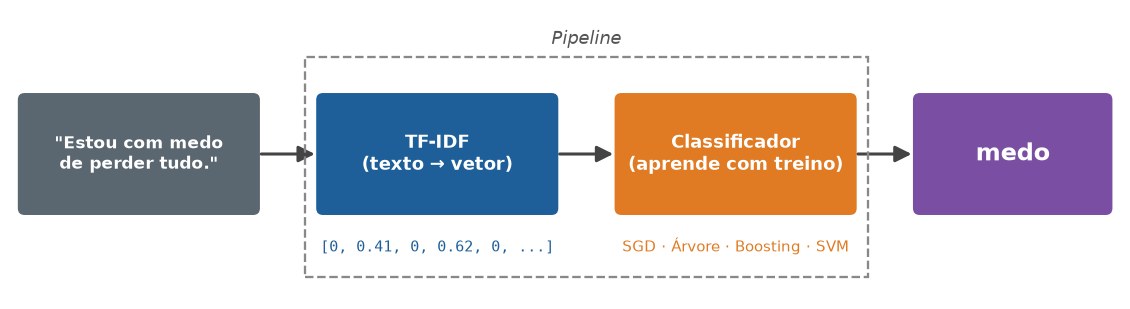

1. A frase vira um **vetor** de números (o TF-IDF das Sessões 05-06).
2. O **classificador** aprende, com as frases de treino, que padrões de números correspondem a cada emoção.
3. Numa frase nova, ele devolve a emoção mais provável.

In [ ]:
# duplicated() marca como True as frases que já apareceram antes; sum() conta quantos True
print("Frases:", len(emocoes), "| repetidas:", emocoes["frase"].duplicated().sum())

# drop_duplicates("frase") apaga as repetições; reset_index(drop=True) renumera as linhas de 0 em diante
emocoes = emocoes.drop_duplicates("frase").reset_index(drop=True)

# value_counts() conta quantas frases existem de cada emoção
print(emocoes["sentimento"].value_counts().to_string())

# sample(4, random_state=3) sorteia 4 frases (sempre as mesmas, por causa da semente 3)
emocoes.sample(4, random_state=3)

Tiramos a frase repetida antes de tudo: se ela caísse uma vez no treino e outra no teste, o modelo "acertaria" uma frase que já viu. É um vazamento pequeno, mas é o tipo de cuidado que deve virar hábito.

Sobram 909 frases, com as quatro emoções em quantidades parecidas.

## 1.2 Separar treino e teste, e calcular o piso

Como nas Sessões 05-06: 80% para treinar, 20% para testar. O `stratify=y` mantém a mesma proporção de cada emoção nos dois lados.

Antes de treinar qualquer modelo, calculamos o **piso**: quanto acerta quem chuta sempre a classe mais comum, sem ler a frase?

Esse "chute" **não é um modelo de verdade**: ninguém o colocaria em uso. Ele é uma **régua**, um número de referência para saber se uma acurácia é boa. Um número de acurácia sozinho não diz nada; depende de quanto se acerta "de graça":

| Base | Acerto "de graça" (chutar sempre a classe mais comum) | Um modelo com 70% é… |
|---|---|---|
| Emoções (hoje, 4 classes equilibradas) | 29% | **muito bom**: 41 pontos acima do piso |
| B2W das Sessões 05-06 (73,5% recomendam) | 73,5% | **quase inútil**: só 3,5 pontos acima |

Os mesmos 70% significam coisas opostas nas duas bases. Por isso o piso vem **antes** de qualquer modelo.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X = emocoes["frase"]          # entrada: o texto
y = emocoes["sentimento"]     # saída esperada: a emoção (o gabarito)

# test_size=0.2 -> 20% para teste; random_state=42 -> sorteio sempre igual; stratify=y -> mesma proporção de emoções
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Treino:", len(X_treino), "| Teste:", len(X_teste))
# conta quantas frases de cada emoção caíram no treino e no teste
balanco = pd.DataFrame({
    "treino (frases)": y_treino.value_counts(),                          # quantidade de cada emoção no treino
    "teste (frases)": y_teste.value_counts(),                            # quantidade de cada emoção no teste
    "treino (%)": (y_treino.value_counts(normalize=True) * 100).round(1),  # normalize=True dá a proporção; *100 vira %
    "teste (%)": (y_teste.value_counts(normalize=True) * 100).round(1),
})
print(balanco)


# mode() devolve o valor mais frequente; [0] pega o primeiro (caso haja empate)
mais_comum = y_treino.mode()[0]

# o "modelo" do piso: uma lista com a mesma emoção repetida para todas as frases do teste
chute = [mais_comum] * len(y_teste)
print(f"Chutar sempre '{mais_comum}': acurácia = {accuracy_score(y_teste, chute):.4f}")

Com quatro classes equilibradas, o piso é baixo: **29%**. Daqui para frente, toda acurácia vai ser lida em comparação com ele: um modelo só aprendeu alguma coisa se ficar bem acima desses 29%.

## 1.3 Uma rodada com quatro algoritmos

| Algoritmo | Ideia em uma frase |
|---|---|
| **SGDClassifier** | Um modelo **linear** (uma soma de pesos, um por palavra) ajustado aos poucos, exemplo a exemplo, pelo *gradiente descendente estocástico*. Com as configurações padrão, ele treina um SVM linear. |
| **Árvore de Decisão** | Uma sequência de perguntas do tipo "a frase tem a palavra *medo*?"; cada resposta leva a uma nova pergunta, até chegar a uma emoção. |
| **Gradient Boosting** | Muitas árvores pequenas treinadas em sequência; cada nova árvore tenta corrigir os erros das anteriores. |
| **SVM** (`SVC`) | Procura a fronteira que separa as classes com a **maior margem** possível; com `kernel="linear"`, a fronteira é "reta" (um hiperplano). |

Todos usam o mesmo TF-IDF, dentro de um `Pipeline`. O `Pipeline` junta o vetorizador e o classificador num objeto só e garante que o TF-IDF aprenda o vocabulário **só com o treino**, sem "espiar" o teste.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC

# dicionário: nome que vai aparecer nas tabelas -> algoritmo (random_state=42 deixa o resultado repetível)
algoritmos = {
    "SGDClassifier": SGDClassifier(random_state=42),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(kernel="linear", random_state=42),
}

previsoes = {}                                    # aqui guardamos as previsões de cada modelo no teste
for nome, clf in algoritmos.items():              # percorre os 4 algoritmos, um por vez
    # monta o pipeline: primeiro o TF-IDF ("tfidf"), depois o classificador ("clf")
    modelo = Pipeline([("tfidf", TfidfVectorizer()), ("clf", clf)])
    # fit: o TF-IDF aprende o vocabulário e o classificador aprende os pesos, só com o treino
    modelo.fit(X_treino, y_treino)
    # predict: prevê a emoção de cada frase do teste
    previsoes[nome] = modelo.predict(X_teste)
    # compara as previsões com o gabarito do teste
    print(f"{nome:<18} acurácia = {accuracy_score(y_teste, previsoes[nome]):.4f}")

💬 **Para pensar antes de seguir:** qual modelo você colocaria no ar? Guarde a resposta; vamos ver se ela se mantém até o fim da Parte 1.

A acurácia é **um número só para o modelo inteiro**. Ela não diz *quais* emoções o modelo acerta e *com quais* ele se confunde. Para isso existe a matriz de confusão.

## 1.4 A matriz de confusão com várias classes

Nas Sessões 05-06 a matriz era 2 × 2. Com quatro classes ela vira 4 × 4, mas a leitura é a mesma: **cada linha é a emoção real (o gabarito), cada coluna é a emoção que o modelo previu**.

Como ler:

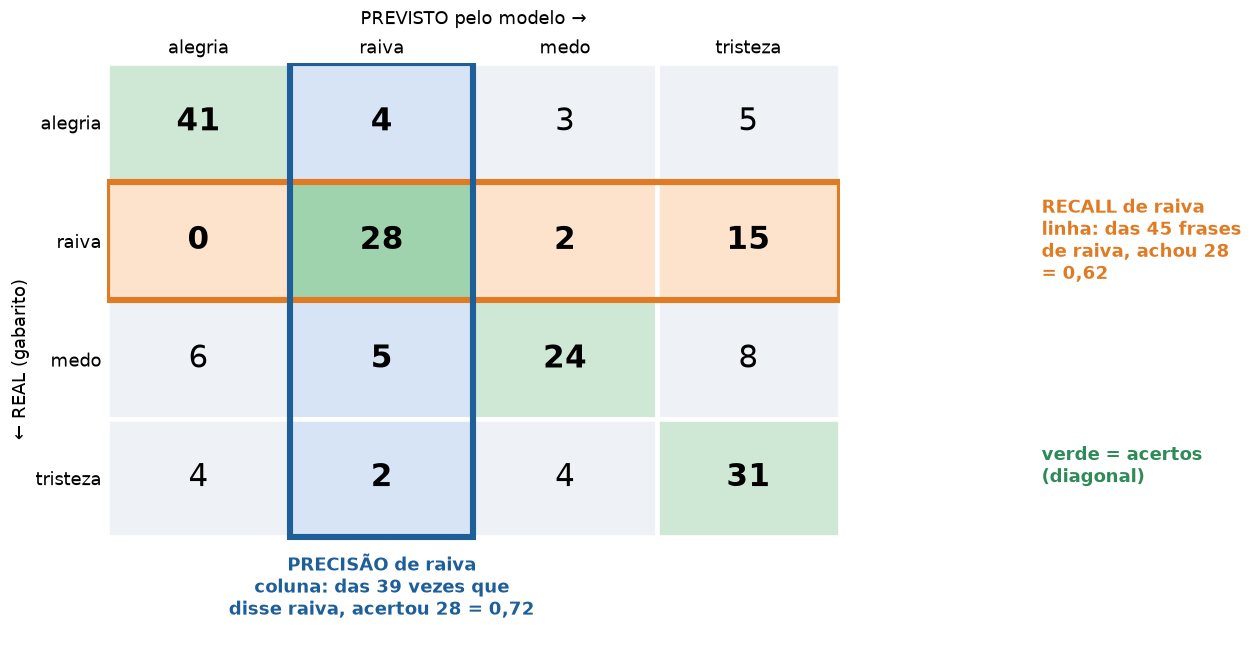

- **A diagonal** (41, 28, 24, 31) são os acertos. Somando, 124 de 182 frases: os 68% de acurácia.
- **Fora da diagonal estão os erros, e eles dizem de que tipo é cada um.** A célula raiva × tristeza = **15** quer dizer: 15 frases que eram de **raiva** o SVM classificou como **tristeza**. É, de longe, a confusão mais frequente.
- **A soma de uma linha** é quantas frases daquela emoção existem no teste: raiva = 0 + 28 + 2 + 15 = 45.
- **A soma de uma coluna** é quantas vezes o modelo **disse** aquela emoção: a coluna tristeza soma 5 + 15 + 8 + 31 = 59. O modelo "chuta tristeza" demais.

Agora as quatro matrizes lado a lado:

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ordem = ["alegria", "raiva", "medo", "tristeza"]       # ordem das linhas e colunas nas matrizes

# cria uma figura com 2 linhas x 2 colunas de gráficos
fig, eixos = plt.subplots(2, 2, figsize=(11, 9))

# eixos.ravel() transforma a grade 2x2 numa lista de 4 gráficos; zip junta cada gráfico com um modelo
for eixo, (nome, pred) in zip(eixos.ravel(), previsoes.items()):
    # desenha a matriz de confusão desse modelo dentro do gráfico "eixo", em tons de azul
    ConfusionMatrixDisplay.from_predictions(y_teste, pred, labels=ordem, ax=eixo, cmap="Blues", colorbar=False)
    # título com o nome do modelo e a acurácia em porcentagem (:.0% formata 0.68 como 68%)
    eixo.set_title(f"{nome} — acurácia {accuracy_score(y_teste, pred):.0%}")
    eixo.set_xlabel("previsto")     # nome do eixo horizontal
    eixo.set_ylabel("real")         # nome do eixo vertical

plt.tight_layout()                  # ajusta os espaços para os títulos não se sobreporem
plt.show()                          # mostra a figura

Quanto mais escura a diagonal e mais clara o resto, melhor:

- **SGDClassifier e SVM** têm a diagonal forte e quase o mesmo padrão de erros: os dois confundem **raiva com tristeza** (12 e 15 frases). Faz sentido: as duas emoções aparecem em frases de frustração. "Me esforço tanto, e no fim sempre sou esquecido" está na base como tristeza, mas daria para ler como raiva.
- **Gradient Boosting** acerta mais **alegria** que todos (45 de 53), mas manda muito **medo** para alegria (12) e muita **tristeza** para medo (10).
- **Árvore de Decisão** espalha erros pela matriz inteira. Até 13 frases de **alegria** viraram **tristeza**, um erro que os outros quase não cometem.

### Por que a árvore vai tão mal?

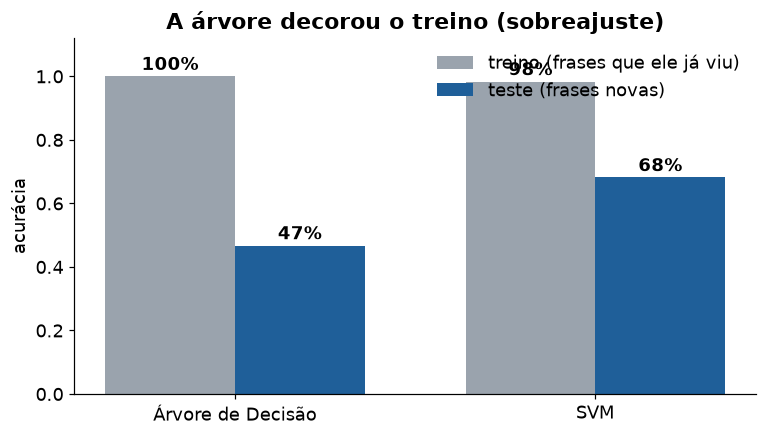

A árvore acerta **100% das frases de treino**, mas só 47% das frases novas. Com 727 frases curtas e mais de 1.600 palavras diferentes, ela aprende regras do tipo "se tem *x* e não tem *y* e tem *z*… então é medo" que só valem para aquelas frases. Ela **decorou** o treino em vez de aprender. Isso se chama **sobreajuste** (*overfitting*).

Dá para conferir:

In [ ]:
# treina cada modelo de novo e compara o acerto nas frases que ele JÁ viu (treino) com as NOVAS (teste)
comparacao_treino_teste = {}
for nome, clf in algoritmos.items():                       # os mesmos 4 algoritmos da seção 1.3
    modelo = Pipeline([("tfidf", TfidfVectorizer()), ("clf", clf)])
    modelo.fit(X_treino, y_treino)
    acc_treino = accuracy_score(y_treino, modelo.predict(X_treino))   # acerto nas frases usadas para aprender
    acc_teste = accuracy_score(y_teste, modelo.predict(X_teste))      # acerto nas frases novas
    comparacao_treino_teste[nome] = {"treino": round(acc_treino, 3),
                                     "teste": round(acc_teste, 3),
                                     "diferença": round(acc_treino - acc_teste, 3)}
pd.DataFrame(comparacao_treino_teste).T                     # .T: um modelo por linha


**A lição**: 100% no treino, sozinho, não prova que foi **overfitting**. O que mostra se o modelo aprendeu é o desempenho em frases que ele não viu, o teste ou a validação cruzada.

## 1.5 Precisão, recall e F1, uma de cada vez

A matriz mostra tudo, mas é difícil comparar 16 números de cada modelo. As métricas resumem a matriz **por classe**. Vamos entender cada uma com a classe **raiva**.

### **A intuição**

Pense no modelo como alguém que precisa "circular" as frases de raiva num monte de frases misturadas. Os pontos vermelhos são as frases que **são** de raiva; o círculo azul é o que o modelo **chamou** de raiva:

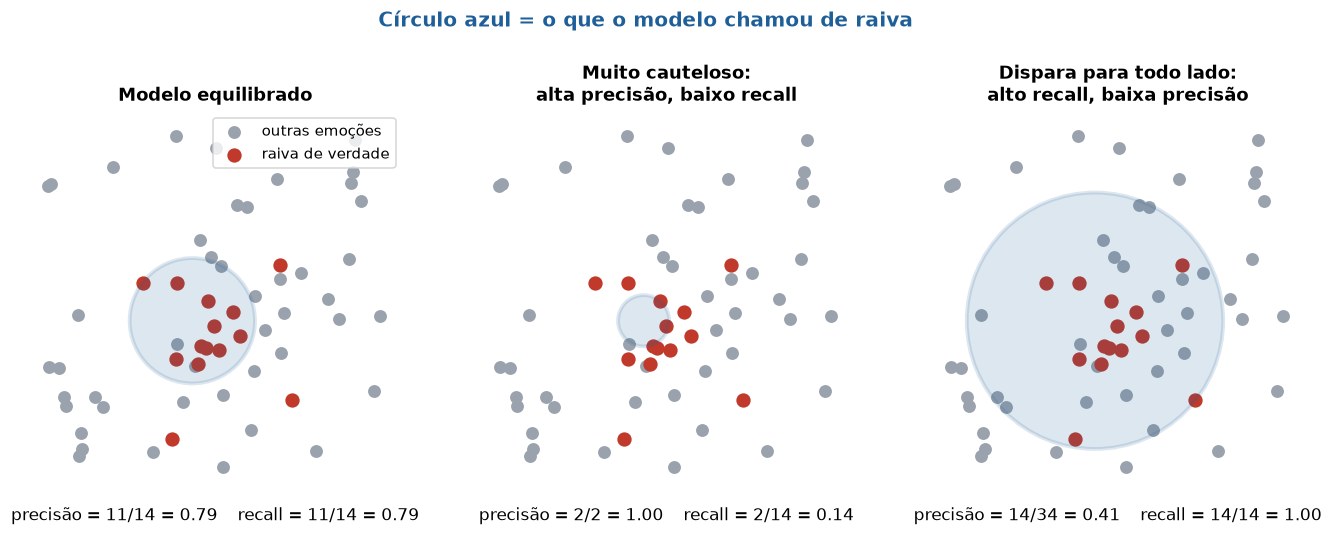

- **Precisão:** *dentro do círculo*, quantos pontos são vermelhos? → "Quando o modelo diz raiva, dá para confiar?"
- **Recall:** *de todos os pontos vermelhos*, quantos ficaram dentro do círculo? → "O modelo encontrou as frases de raiva?"

Um modelo cauteloso (círculo pequeno) quase nunca erra quando fala, mas deixa muita coisa de fora. Um modelo que dispara para todo lado (círculo enorme) não deixa nada de fora, mas erra muito.

### A conta, na matriz do SVM

- **Precisão** olha a **coluna** raiva: das 39 vezes que o modelo disse "raiva", 28 eram raiva. As outras 11 (4 de alegria, 5 de medo, 2 de tristeza) são os **falsos positivos**.
- **Recall** olha a **linha** raiva: das 45 frases que eram raiva, o modelo encontrou 28. As outras 17 (2 viraram medo, 15 viraram tristeza) são os **falsos negativos**.

In [ ]:
# a matriz do SVM em forma de tabela, para pegar os números da conta
matriz_svm = pd.DataFrame(confusion_matrix(y_teste, previsoes["SVM"], labels=ordem),
                          index=ordem, columns=ordem)   # linhas = real, colunas = previsto

acertos = matriz_svm.loc["raiva", "raiva"]          # célula da diagonal: era raiva e o modelo disse raiva
previstos_raiva = matriz_svm["raiva"].sum()         # soma da COLUNA raiva: tudo que o modelo chamou de raiva
reais_raiva = matriz_svm.loc["raiva"].sum()         # soma da LINHA raiva: todas as frases que eram raiva

precisao = acertos / previstos_raiva                # dos que ele disse raiva, quantos eram
recall = acertos / reais_raiva                      # das que eram raiva, quantas ele achou
f1 = 2 * precisao * recall / (precisao + recall)    # média harmônica dos dois (explicada abaixo)

print(f"raiva: acertos = {acertos} | previstos como raiva = {previstos_raiva} | realmente raiva = {reais_raiva}")
print(f"precisão = {acertos}/{previstos_raiva} = {precisao:.2f}")
print(f"recall   = {acertos}/{reais_raiva} = {recall:.2f}")
print(f"F1       = 2 × {precisao:.2f} × {recall:.2f} / ({precisao:.2f} + {recall:.2f}) = {f1:.2f}")

### F1: um número só, que só fica alto se as duas forem altas

O **F1** é a **média harmônica** de precisão e recall:

$$F1 = \frac{2 \times \text{precisão} \times \text{recall}}{\text{precisão} + \text{recall}}$$

Por que não a média comum? Porque ela esconde o desastre. Imagine um modelo que disse "raiva" **uma única vez**, numa frase óbvia como "que ódio!":

- precisão = 1/1 = **100%** (acertou a única vez que falou);
- recall = 1/45 = **2%** (achou só 1 das 45 frases de raiva).

A média comum daria 0,51, parecendo "metade bom". O F1 dá **0,04**:

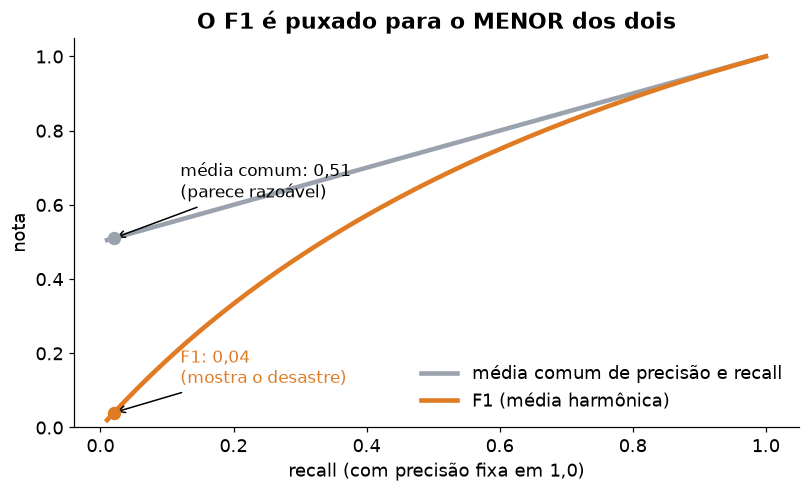

A média harmônica é puxada para o **menor** dos dois valores: não dá para compensar um recall péssimo com uma precisão ótima.

### O `classification_report`

Esse cálculo, para todas as classes de uma vez:

In [ ]:
from sklearn.metrics import classification_report

for nome, pred in previsoes.items():              # percorre os 4 algoritmos (SGD, Árvore, Boosting, SVM)
    print("=" * 60)                               # linha separadora entre um relatório e outro
    print(nome)                                   # nome do algoritmo
    print("=" * 60)
    # digits=2 mostra 2 casas decimais; as classes aparecem em ordem alfabética
    print(classification_report(y_teste, pred, digits=2))


Linha por linha:

| Linha / coluna | O que significa |
|---|---|
| **precision, recall, f1-score** de cada emoção | O que calculamos acima. A linha raiva mostra 0,72 / 0,62 / 0,67, os mesmos números da conta na mão. |
| **support** | Quantas frases daquela emoção existem **no teste** (a soma da linha da matriz). Não é uma medida de qualidade; serve para saber quanto confiar no número. Uma métrica calculada com 41 frases oscila mais do que uma calculada com 4.000. |
| **accuracy** | A acurácia de sempre: acertos / total = 124 / 182. |
| **macro avg** | A média simples das quatro classes, **todas com o mesmo peso**. É a mais justa quando todas as classes importam igualmente. É o "**F1 macro**" que vamos usar daqui em diante. |
| **weighted avg** | A média **ponderada pelo support**: classes com mais frases pesam mais. Fica sempre perto da acurácia e, numa base desbalanceada, pode esconder uma classe pequena que vai mal. |

O que o relatório revela que a acurácia não mostrava:

- **tristeza** tem o maior recall do SVM (0,76: encontra três de cada quatro frases tristes), mas a pior precisão (0,53: quase metade das vezes que diz "tristeza", erra). É o efeito daquelas 15 frases de raiva que caíram na coluna tristeza.
- **medo** é o contrário: quando o SVM diz medo, costuma acertar (0,73), mas deixa passar quase metade das frases de medo (recall 0,56).

💬 **Para a turma:** num sistema que encaminha mensagens com **medo** para um atendimento de apoio, o que é pior: precisão baixa ou recall baixo?

## 1.6 Comparando os quatro modelos pelas métricas

In [ ]:
from sklearn.metrics import f1_score

resumo = {}                                          # nome do modelo -> lista de números da tabela
for nome, pred in previsoes.items():                 # percorre as previsões de cada modelo
    # average=None devolve um F1 para cada emoção, na ordem de "labels"
    f1_por_emocao = list(f1_score(y_teste, pred, labels=ordem, average=None))
    # average="macro": média simples dos 4 F1
    f1_macro = f1_score(y_teste, pred, average="macro")
    resumo[nome] = f1_por_emocao + [f1_macro, accuracy_score(y_teste, pred)]

# monta a tabela: uma coluna por modelo, uma linha por métrica; round(2) arredonda para 2 casas
pd.DataFrame(resumo, index=[f"F1 {e}" for e in ordem] + ["F1 macro", "acurácia"]).round(2)

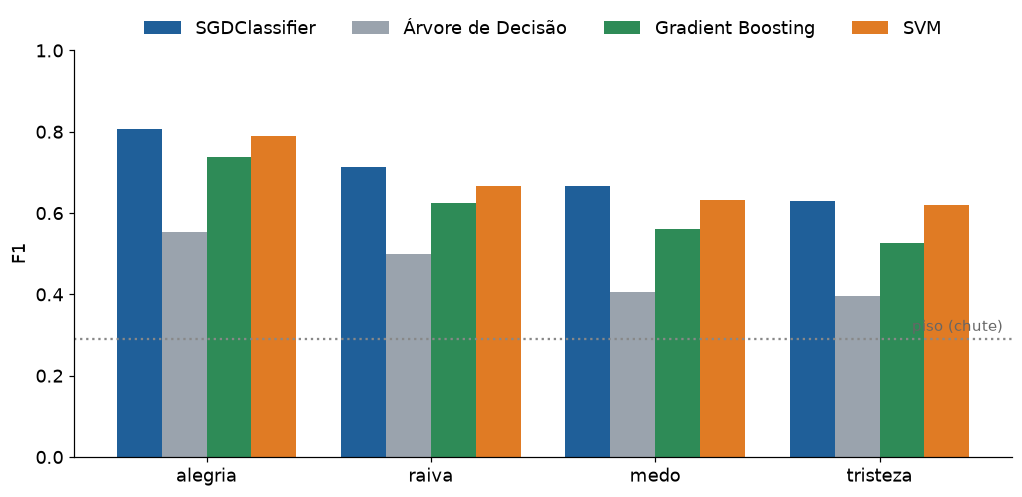

- **Alegria é a emoção mais fácil para todos os modelos**: palavras como "consegui", "ganhei", "felicidade" quase não aparecem nas outras emoções.
- **Medo e tristeza são as mais difíceis** para todos os quatro, e se confundem entre si: no SVM, 8 frases de medo viraram tristeza; no SGDClassifier, 6 para cada lado.
- Nesta divisão, o SGDClassifier ganhou em todas as linhas. Mas a diferença para o SVM é de 1 a 4 pontos, em classes com 41 a 53 frases. Será que dá para confiar nessa vitória?

## 1.7 Um número só pode enganar

Até agora fizemos **uma** divisão treino/teste (`random_state=42`). Vamos repetir exatamente o mesmo experimento com o SVM, mudando só a semente da divisão:

In [ ]:
for semente in [1, 2, 3, 4, 5]:                      # 5 sorteios diferentes de treino/teste
    # mesma proporção 80/20, mas cada semente sorteia frases diferentes para o teste
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=semente, stratify=y)
    # treina o mesmo SVM nesse novo treino
    m = Pipeline([("tfidf", TfidfVectorizer()), ("clf", SVC(kernel="linear"))]).fit(Xa, ya)
    # mede no novo teste
    print(f"divisão {semente}: acurácia do SVM = {accuracy_score(yb, m.predict(Xb)):.4f}")

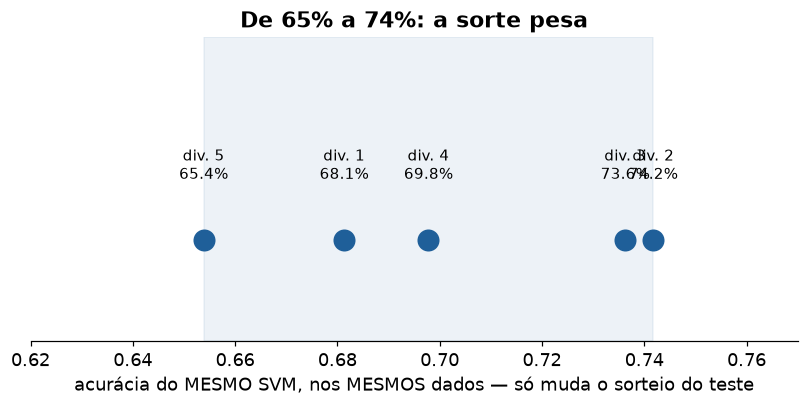

O **mesmo modelo, nos mesmos dados**, vai de 65% a 74%, só porque as 182 frases sorteadas para o teste mudaram. Uma variação de quase 9 pontos. Com uma base pequena, a sorte da divisão pesa mais do que a diferença entre SGDClassifier e SVM.

## 1.8 Validação cruzada

A solução é não depender de uma divisão só. Na **validação cruzada com k partes** (*k-fold cross-validation*), o treino é dividido em k partes; o modelo é treinado k vezes, cada vez deixando uma parte diferente de fora para avaliar:

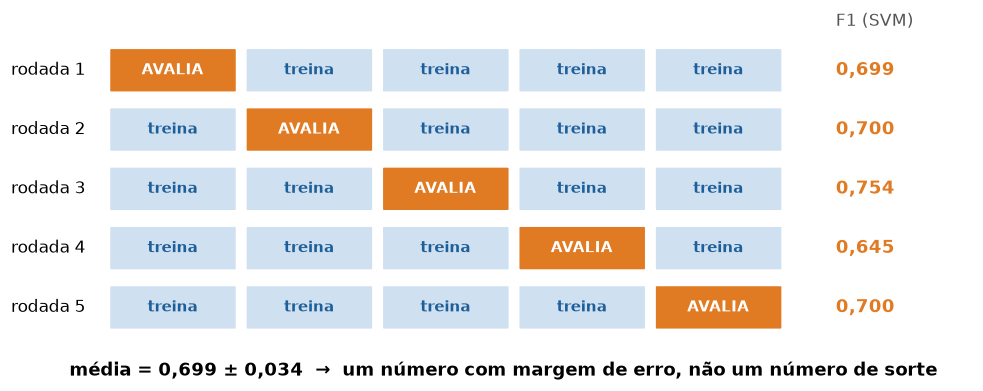

O resultado é uma **média com desvio-padrão**, em vez de um número de sorte. O `StratifiedKFold` mantém a proporção de cada emoção em todas as partes.

A validação cruzada roda **só no treino**: o teste continua guardado.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 5 partes; shuffle=True embaralha antes de dividir; random_state=42 deixa repetível
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nome, clf in algoritmos.items():                 # percorre os 4 algoritmos
    pipe = Pipeline([("tfidf", TfidfVectorizer()), ("clf", clf)])
    # treina e avalia 5 vezes, uma para cada parte deixada de fora; devolve os 5 F1 macro
    notas = cross_val_score(pipe, X_treino, y_treino, cv=cv, scoring="f1_macro")
    # mean() = média das 5 notas; std() = desvio-padrão (o quanto elas variam)
    print(f"{nome:<18} F1 macro = {notas.mean():.3f} ± {notas.std():.3f}   partes: {np.round(notas, 3)}")

Agora a ordem muda: na média, o **SVM fica ligeiramente à frente** do SGDClassifier (0,699 contra 0,680), o contrário do que a divisão única mostrou. Mas a diferença (0,02) é menor que a variação de cada um (± 0,02 e ± 0,03).

A conclusão honesta é: **SVM e SGDClassifier empatam**. Já a distância para o Gradient Boosting (0,58) e para a Árvore (0,45) é grande e aparece em todas as partes: esses dois são piores de verdade nesta tarefa.

💬 E a sua resposta da seção 1.3 — mudou?

## 1.9 CountVectorizer ou TF-IDF?

Até aqui usamos só o TF-IDF. Nas Sessões 05-06 vimos os dois jeitos de transformar texto em número:

- **CountVectorizer** conta quantas vezes cada palavra aparece na frase;
- **TfidfVectorizer** faz a mesma contagem, mas dá menos peso às palavras que aparecem em muitas frases.

Com a validação cruzada dá para comparar sem depender da sorte de uma divisão:

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

comparacao = {}                                       # vetorizador -> {algoritmo: nota}
for nome_vet, Vetorizador in [("CountVectorizer", CountVectorizer), ("TfidfVectorizer", TfidfVectorizer)]:
    comparacao[nome_vet] = {}
    for nome, clf in algoritmos.items():              # os mesmos 4 algoritmos com cada vetorizador
        # Vetorizador() cria um vetorizador novo, do tipo da vez
        notas = cross_val_score(Pipeline([("vet", Vetorizador()), ("clf", clf)]),
                                X_treino, y_treino, cv=cv, scoring="f1_macro")
        comparacao[nome_vet][nome] = f"{notas.mean():.3f} ± {notas.std():.3f}"
pd.DataFrame(comparacao)

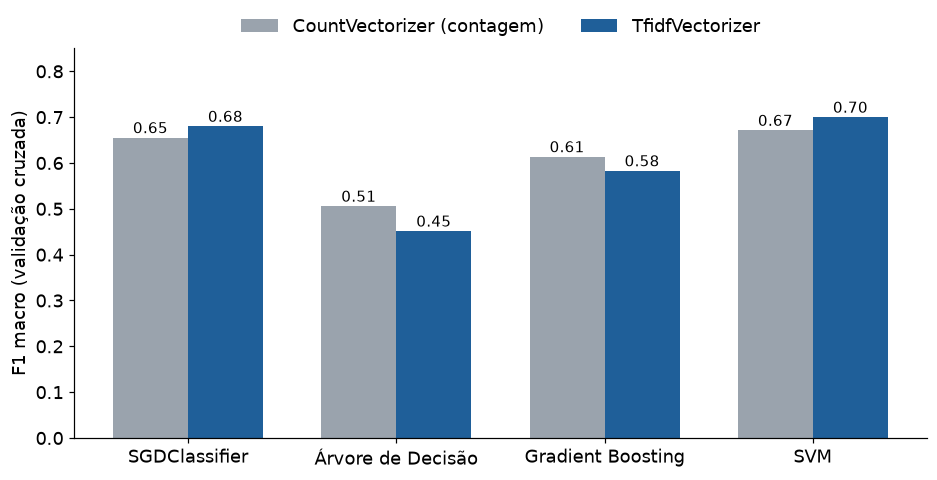

Não existe um vencedor geral, e o padrão é interessante:

- **Nos modelos lineares (SGDClassifier e SVM), o TF-IDF ganha.** Eles somam um peso por palavra; com o TF-IDF, as palavras que aparecem em muitas frases de todas as emoções já chegam valendo pouco, e o modelo se concentra nas que diferenciam as emoções.
- **Nos modelos de árvore (Árvore e Gradient Boosting), a contagem simples ganha.** Uma árvore faz perguntas do tipo "esta palavra aparece mais de *x* vezes?". Com contagens, "medo" numa frase vale 1 (ou 2, se aparecer duas vezes); com TF-IDF, o mesmo "medo" vale um número diferente em cada frase, dependendo do tamanho dela e das outras palavras. É uma explicação provável: o teste mostra o resultado, não prova a causa.

Um detalhe que reforça a seção 1.7: numa divisão única (a de `random_state=42`), o SVM parecia **melhor** com CountVectorizer (F1 0,699 contra 0,677). Na validação cruzada, é o contrário. Mais um motivo para não decidir com um número só.


## 1.10 Com ou sem pré-processamento?

Até aqui as frases entraram no TF-IDF do jeito que estão na planilha. Nas Sessões 03-04 vimos várias formas de preparar o texto antes de vetorizar. Será que ajudam aqui?

Vamos montar **seis versões** do texto, cada uma com uma etapa a mais, e comparar com a validação cruzada, nos mesmos 4 algoritmos:

| Versão | O que faz |
|---|---|
| 1. sem pré-processamento | A frase como está na planilha. (O TF-IDF já põe em minúsculas e ignora a pontuação sozinho.) |
| 2. limpeza | Minúsculas, sem números e sem pontuação. |
| 3. + stopwords | Tira as palavras muito comuns da lista do NLTK ("de", "que", "com", "ao"…). |
| 4. + stopwords, mantendo negações | Igual à 3, mas **devolve** "não", "nem", "nunca", "sem"… |
| 5. + stemming (RSLP) | Corta cada palavra no radical: "preocupado" → "preocup". |
| 6. + lematização (spaCy) | Troca cada palavra pela forma de dicionário: "preocupado" → "preocupar". |

Primeiro, montamos as seis versões de todas as frases:

In [ ]:
import nltk
nltk.download("stopwords", quiet=True)               # lista de stopwords do NLTK (Sessões 03-04)
nltk.download("rslp", quiet=True)                    # o stemmer RSLP, feito para o português
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer
import spacy

try:                                                 # tenta carregar o modelo de português do spaCy...
    nlp = spacy.load("pt_core_news_sm")
except OSError:                                      # ...se ele ainda não estiver instalado (no Colab, na 1ª vez)...
    spacy.cli.download("pt_core_news_sm")            # ...baixa o modelo (leva alguns segundos)
    nlp = spacy.load("pt_core_news_sm")

stop = set(stopwords.words("portuguese"))            # as stopwords do português
negacoes = {"não", "nem", "nunca", "jamais", "nada", "ninguém", "nenhum", "nenhuma", "sem"}
print("Negações que estão na lista de stopwords do NLTK:", sorted(negacoes & stop))
stop_sem_negacao = stop - negacoes                   # a mesma lista, mas sem as negações
stemmer = RSLPStemmer()

def limpar_frase(texto):
    texto = texto.lower()                            # 1. tudo minúsculo
    texto = re.sub(r"\d+", " ", texto)               # 2. apaga os números
    texto = re.sub(r"[^a-zà-ÿ\s]", " ", texto)       # 3. apaga o que não for letra ou espaço (pontuação)
    return re.sub(r"\s+", " ", texto).strip()        # 4. junta espaços repetidos

def tirar_stopwords(texto, lista):
    # mantém só as palavras que NÃO estão na lista de stopwords recebida
    return " ".join(p for p in texto.split() if p not in lista)

# cada versão vira uma coluna nova da tabela emocoes
emocoes["v2_limpeza"] = emocoes["frase"].apply(limpar_frase)
emocoes["v3_stopwords"] = emocoes["v2_limpeza"].apply(lambda t: tirar_stopwords(t, stop))
emocoes["v4_stop_negacao"] = emocoes["v2_limpeza"].apply(lambda t: tirar_stopwords(t, stop_sem_negacao))
# stemming: aplica o RSLP palavra por palavra
emocoes["v5_stemming"] = emocoes["v4_stop_negacao"].apply(lambda t: " ".join(stemmer.stem(p) for p in t.split()))
# lematização: nlp.pipe processa todas as frases de uma vez; lemma_ é a forma de dicionário de cada palavra
emocoes["v6_lematizacao"] = [" ".join(tok.lemma_.lower() for tok in doc)
                             for doc in nlp.pipe(emocoes["v4_stop_negacao"])]

# mostra o que cada versão faz com uma frase que tem "Não"
exemplo = emocoes[emocoes["frase"].str.startswith("Não consegui dormir")].iloc[0]
for coluna in ["frase", "v2_limpeza", "v3_stopwords", "v4_stop_negacao", "v5_stemming", "v6_lematizacao"]:
    print(f"{coluna:<16}", exemplo[coluna])

Repare na versão 3: a lista do NLTK **apagou o "não"**, e "Não consegui dormir" virou "consegui dormir", o contrário do que a frase diz. É por isso que existe a versão 4.

Agora a comparação. Cada versão passa pelos mesmos 4 algoritmos, com a mesma validação cruzada da seção 1.8 (esta célula leva um ou dois minutos, por causa do Gradient Boosting):

In [ ]:
versoes = {"1. sem pré-processamento": "frase",
           "2. limpeza": "v2_limpeza",
           "3. + stopwords": "v3_stopwords",
           "4. + stopwords, mantendo negações": "v4_stop_negacao",
           "5. + stemming (RSLP)": "v5_stemming",
           "6. + lematização (spaCy)": "v6_lematizacao"}

resultado = {}                                       # versão -> {algoritmo: nota}
for nome_versao, coluna in versoes.items():          # percorre as 6 versões do texto
    # as MESMAS frases de treino de antes (X_treino.index), só que na versão da vez
    textos_treino = emocoes.loc[X_treino.index, coluna]
    resultado[nome_versao] = {}
    for nome, clf in algoritmos.items():             # os mesmos 4 algoritmos
        pipe = Pipeline([("tfidf", TfidfVectorizer()), ("clf", clf)])
        notas = cross_val_score(pipe, textos_treino, y_treino, cv=cv, scoring="f1_macro")
        resultado[nome_versao][nome] = f"{notas.mean():.3f} ± {notas.std():.3f}"
    # tamanho do vocabulário: quantas palavras diferentes sobram nessa versão
    resultado[nome_versao]["vocabulário"] = len(TfidfVectorizer().fit(textos_treino).vocabulary_)

pd.DataFrame(resultado).T                            # .T vira a tabela: uma linha por versão

Três lições:

1. **A limpeza não mudou nada**, número por número. O `TfidfVectorizer` já põe tudo em minúsculas e ignora a pontuação sozinho; limpar antes foi trabalho repetido.
2. **Nos modelos lineares (SGDClassifier e SVM), nenhuma versão ganha de verdade.** As diferenças (±0,02) são do tamanho da variação entre as partes da validação cruzada. Tirar as stopwords até **piorou o SVM** (0,699 → 0,674), porque levou junto "não", "nem" e "sem"; devolver as negações recupera uma parte.
3. **Nos modelos de árvore, o pré-processamento ajuda muito.** A Árvore sobe de 0,451 para 0,550 com stemming, e o vocabulário cai de 1.652 para 1.061 palavras. Juntando "preocupado", "preocupada" e "preocupação" numa coisa só, a árvore precisa de menos perguntas e decora menos o treino.

**Conclusão:** pré-processamento não é regra, é uma escolha que se testa. O efeito depende do modelo, e uma etapa "padrão" pode apagar justamente a informação que importa, como aconteceu com o "não".

## 1.11 Escolher hiperparâmetros sem usar o teste: `GridSearchCV`

Todo modelo tem **hiperparâmetros**, escolhas que não são aprendidas dos dados:
- usar ou não bigramas (`ngram_range`);
- ignorar palavras raras (`min_df`);
- o quanto o SVM pode se ajustar aos dados (`C`).

A tentação é testar cada combinação no conjunto de teste e ficar com a melhor. Só que aí o teste deixou de ser "dados que o modelo nunca viu": você escolheu o modelo **olhando** para ele, e o número final fica otimista.

O `GridSearchCV` testa todas as combinações de uma grade usando **validação cruzada dentro do treino**. O teste é usado **uma vez só**, no fim.

In [ ]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([("tfidf", TfidfVectorizer()), ("clf", SVC(kernel="linear"))])

# a grade: o nome de cada parâmetro é "nome do passo" + "__" + "nome do parâmetro"
grade = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],   # só palavras isoladas, ou palavras + pares de palavras
    "tfidf__min_df": [1, 2],                  # 2 = ignora palavras que aparecem em só uma frase
    "clf__C": [0.1, 1, 10],                   # C maior = o SVM tenta acertar mais o treino
}
# testa as 2 x 2 x 3 = 12 combinações, cada uma com validação cruzada de 5 partes, escolhendo pelo F1 macro
busca = GridSearchCV(pipe, grade, cv=cv, scoring="f1_macro")
busca.fit(X_treino, y_treino)                  # tudo isso só com o treino

print("Melhor combinação:", busca.best_params_)
print("F1 macro na validação cruzada:", round(busca.best_score_, 3))

# agora, e só agora, o teste: a busca já guarda o melhor modelo treinado
pred_final = busca.predict(X_teste)
print("No teste: acurácia =", round(accuracy_score(y_teste, pred_final), 4),
      "| F1 macro =", round(f1_score(y_teste, pred_final, average="macro"), 4))

A busca escolheu bigramas e `C=10`. O ganho sobre o SVM padrão é pequeno (0,703 contra 0,699 na validação cruzada), e o F1 no teste (0,698) ficou **perto do que a validação cruzada previu**. É isso que se espera quando o teste não foi usado para escolher nada.

## 1.12 Probabilidade e limiar de decisão

Até aqui o modelo sempre deu **uma resposta**. Mas muitos classificadores conseguem dar uma **probabilidade**, e a decisão final depende de um **limiar**: por padrão, "é raiva se a probabilidade passar de 50%". Esse limiar é uma escolha de negócio, não de matemática.

**Cenário:** um serviço de atendimento quer **sinalizar mensagens com raiva** para alguém responder primeiro. Deixar passar um cliente furioso é pior do que sinalizar uma mensagem a mais.

Transformamos o problema em binário (raiva × resto) e usamos o SGDClassifier com `loss="log_loss"`, que é uma regressão logística treinada pelo mesmo método e tem `predict_proba`.

In [ ]:
from sklearn.metrics import recall_score, precision_score

# rótulo binário: 1 se a frase é raiva, 0 se é qualquer outra emoção
raiva_treino = (y_treino == "raiva").astype(int)
raiva_teste = (y_teste == "raiva").astype(int)

# log_loss transforma o SGDClassifier numa regressão logística, que sabe dar probabilidades
alerta = Pipeline([("tfidf", TfidfVectorizer()), ("clf", SGDClassifier(loss="log_loss", random_state=42))])
alerta.fit(X_treino, raiva_treino)

# predict_proba devolve duas colunas: [prob. de não ser raiva, prob. de ser raiva]; [:, 1] pega a segunda
prob_raiva = alerta.predict_proba(X_teste)[:, 1]

for limiar in [0.5, 0.4, 0.3, 0.2]:                   # testa 4 limiares
    p = (prob_raiva >= limiar).astype(int)            # 1 (alerta) se a probabilidade passou do limiar
    print(f"limiar {limiar}: recall = {recall_score(raiva_teste, p):.3f}   "
          f"precisão = {precision_score(raiva_teste, p):.3f}   "
          f"frases sinalizadas = {p.sum()} (com raiva de verdade: {raiva_teste.sum()})")

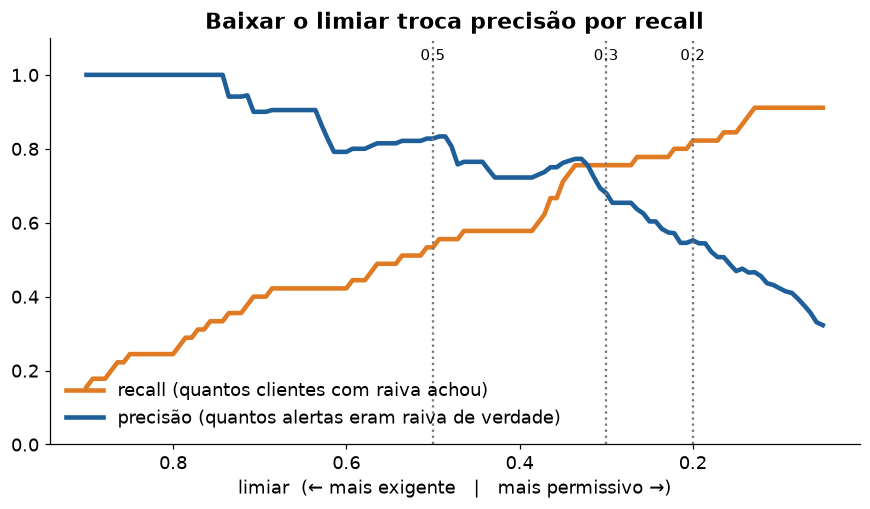

- Com o limiar padrão (0,5), o alerta acerta 83% das vezes que dispara, mas **deixa passar quase metade** dos clientes com raiva (recall 0,53).
- Baixando para 0,3, ele encontra três em cada quatro, com uma precisão ainda razoável.
- Baixando para 0,2, encontra 82%, mas quase metade dos alertas é alarme falso.

Não existe limiar "certo". Existe o limiar que equilibra o custo de **deixar passar** (falso negativo) contra o custo de **alarme falso** (falso positivo) **naquela situação**. Num filtro de spam, você prefere o contrário: melhor deixar passar um spam do que jogar fora um e-mail importante.

💬 **Para a turma:** qual limiar vocês escolheriam para o atendimento? E para bloquear automaticamente a conta de um cliente?

## 1.13 Abrindo a caixa: o que o modelo aprendeu

Um modelo linear como o SGDClassifier dá um **peso** a cada palavra, para cada emoção. As palavras de maior peso mostram em que o modelo se baseia:

In [ ]:
sgd = Pipeline([("tfidf", TfidfVectorizer()), ("clf", SGDClassifier(random_state=42))])
sgd.fit(X_treino, y_treino)

# get_feature_names_out() devolve as palavras do vocabulário, na mesma ordem das colunas do TF-IDF
vocab = np.array(sgd.named_steps["tfidf"].get_feature_names_out())
# coef_ tem uma linha de pesos por emoção e uma coluna por palavra
pesos = sgd.named_steps["clf"].coef_

for i, emocao in enumerate(sgd.named_steps["clf"].classes_):   # classes_ = as emoções, em ordem alfabética
    # argsort() ordena do menor para o maior; [::-1] inverte; [:10] pega as 10 palavras de maior peso
    top10 = vocab[np.argsort(pesos[i])[::-1][:10]]
    print(f"{emocao:<9}", ", ".join(top10))

Muitas palavras fazem sentido ("socorro", "aterrorizado", "ódio", "saudade"). Mas repare em **tristeza**: "mais", "mas", "fim", "tudo". São palavras comuns que, **nesta base**, aparecem mais em frases tristes do que nas outras emoções:

- "Tentei ser forte, **mas** hoje só consigo chorar"
- "meu sonho empreendedor chegou ao **fim**"
- "Às vezes, **tudo** parece perdido"

"Fim", por exemplo, está em 7 frases de tristeza e em só 2 das outras três emoções juntas. O modelo aprendeu um **atalho**: funciona aqui, mas uma frase de alegria com "mas" e "tudo" leva um empurrão para tristeza. E "não" aparece entre as palavras de **medo**, o que já anuncia um problema.

Olhar os pesos é a forma mais barata de desconfiar de um modelo.

## 1.14 Salvar o modelo e usar depois

Treinar dá trabalho; usar deve ser fácil. O `joblib` salva o modelo num arquivo, que pode ser carregado em outro programa, por exemplo num sistema que recebe mensagens novas todos os dias.

O que vamos salvar é o `busca.best_estimator_` da seção 1.11. Depois de testar as 12 combinações, o `GridSearchCV` **treina de novo** a melhor delas (bigramas e `C=10`) com **todo o treino** e guarda o resultado ali. E o que ele guarda é o **pipeline inteiro**:

```
Pipeline
├── "tfidf": TfidfVectorizer(ngram_range=(1, 2))   ← com o vocabulário e os pesos IDF aprendidos no treino
└── "clf":   SVC(kernel="linear", C=10)             ← com o modelo treinado
```

Por isso o arquivo salvo recebe **frases cruas**: ele mesmo transforma a frase em vetor e depois classifica. Se salvássemos só o classificador, o sistema que fosse usar o modelo teria que recriar o TF-IDF exatamente igual, com o mesmo vocabulário, senão os números não batem. Salvando o pipeline, não há como errar.

In [ ]:
import joblib

joblib.dump(busca.best_estimator_, "modelo_emocoes.joblib")   # salva o melhor modelo da busca num arquivo
modelo_carregado = joblib.load("modelo_emocoes.joblib")        # carrega o arquivo (poderia ser em outro programa)

novas = ["Que dia maravilhoso, consegui o emprego!",
         "Estou com medo de perder tudo.",
         "Que absurdo, me cobraram duas vezes!",
         "Sinto muita falta da minha avó.",
         "Não estou feliz com o resultado.",
         "Estou com muito sono.",
         "Esse sorvete estava delicioso",
         "Esse batom não presta, quase não fica na boca, sai muito rápido"]

# predict recebe a lista de frases e devolve uma emoção para cada uma; zip junta frase e emoção
for frase, emocao in zip(novas, modelo_carregado.predict(novas)):
    print(f"{emocao:<9} <- {frase}")

# o arquivo guardou o pipeline inteiro: o vetorizador (com o vocabulário aprendido) e o classificador
print()
print(modelo_carregado.named_steps)
print("Palavras e pares de palavras no vocabulário salvo:",
      len(modelo_carregado.named_steps["tfidf"].vocabulary_))

Três acertos e dois erros que ensinam:

- **"Que absurdo, me cobraram duas vezes!"** é raiva, mas virou **tristeza**: a mesma confusão raiva → tristeza da matriz de confusão, agora numa frase nova.
- **"Não estou feliz com o resultado."** identificou como **medo**. O modelo não entende negação: "não" pesa para medo e "feliz" não pesou o suficiente para alegria. É o mesmo problema do léxico das Sessões 05-06: contar palavras, com ou sem Machine Learning, não captura "não + feliz".

⚠️ Um arquivo `.joblib` só deve ser carregado se veio de uma fonte confiável: carregar um arquivo desses pode executar código.

✏️ **Experimente:** escreva 3 frases suas na lista `novas` e rode de novo. Ache um erro e tente explicá-lo pela matriz de confusão ou pelos pesos.

- **"Esse sorvete estava delicioso"** identificou como **raiva**. provavelmente não havia frases no treinamento que indicavam algo do tipo, o modelo não conhece essas palavras, então ele provavelmente vai chutar o que acha, nossa base é muito pequena para um universo de tantos rótulos.

---
# Parte 2 — Quando não há rótulo: aprendizado não supervisionado

## 2.1 A diferença

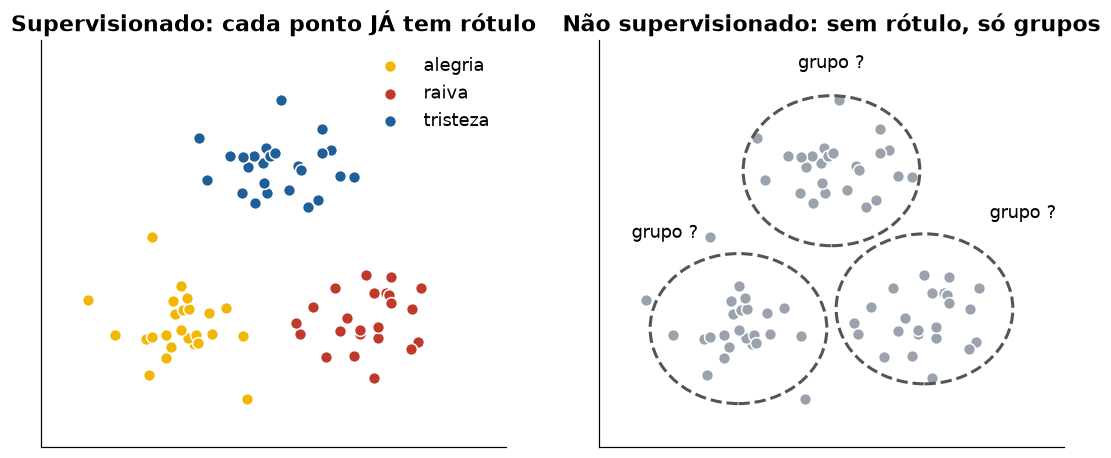

| | Supervisionado (Parte 1) | Não supervisionado (Parte 2) |
|---|---|---|
| O que precisa | Textos **com** rótulo (gabarito) | Só os textos |
| O que faz | Aprende a prever o rótulo | Encontra grupos ou temas parecidos |
| Exemplo de hoje | Prever a emoção de uma frase | Agrupar projetos de lei sem saber o tema |
| Como avaliar | Comparar com o gabarito (matriz, F1…) | Ler os grupos e julgar se fazem sentido |

Rotular textos custa caro: alguém precisa ler cada um. As 909 frases da Parte 1 foram rotuladas uma a uma. Mas imagine o arquivo de um escritório com 50 mil contratos sem classificação nenhuma: por onde começar? É aí que entra o agrupamento.

O problema desta parte é **triagem de documentos jurídicos**: o mesmo tipo de tarefa de um tribunal que precisa mandar cada processo para a vara certa.

## 2.2 A base: Projetos de Lei da Câmara dos Deputados

Todo projeto de lei (PL) apresentado na Câmara tem uma **ementa** (um resumo de uma ou duas frases do que ele propõe) e recebe um ou mais **temas** oficiais (Saúde, Educação, Direito Penal…). A Câmara publica tudo isso como dados abertos, em arquivos CSV, um por ano: [dadosabertos.camara.leg.br](https://dadosabertos.camara.leg.br/).

Usamos os PL de 2023 e 2024 que receberam **um único tema**, nos **6 temas mais frequentes**. Esses dados já estão prontos na planilha `projetos_de_lei.xlsx` (extraída em 21/10/2026), com três colunas: o `id` do projeto, a `ementa` e o `tema` oficial.

<details>
<summary><b>Como a planilha foi montada</b> (clique para ver o código; não precisa rodar)</summary>

A Câmara publica um arquivo de proposições e um de temas por ano. Para montar a planilha, baixamos os dois, ficamos só com os projetos de lei (PL), juntamos ementa e tema pelo `id`, mantivemos os projetos com um só tema e os 6 temas mais frequentes:

```python
partes = []
for ano in [2023, 2024]:
    prop = pd.read_csv(f"https://dadosabertos.camara.leg.br/arquivos/proposicoes/csv/proposicoes-{ano}.csv",
                       sep=";", low_memory=False)
    temas = pd.read_csv(f"https://dadosabertos.camara.leg.br/arquivos/proposicoesTemas/csv/proposicoesTemas-{ano}.csv",
                        sep=";", low_memory=False)
    prop = prop[prop["siglaTipo"] == "PL"][["id", "ementa"]]
    temas["id"] = temas["uriProposicao"].str.rsplit("/", n=1).str[-1].astype(int)
    partes.append(prop.merge(temas[["id", "tema"]], on="id"))
pl = pd.concat(partes)
qtd_temas = pl.groupby("id")["tema"].nunique()
pl = pl[pl["id"].isin(qtd_temas[qtd_temas == 1].index)].drop_duplicates("id")
seis = pl["tema"].value_counts().head(6).index
base = pl[pl["tema"].isin(seis)].reset_index(drop=True)
base["ementa"] = base["ementa"].str.replace(r"\s+", " ", regex=True).str.strip()
base.to_excel("projetos_de_lei.xlsx", index=False)
```

Se você rodar esse código hoje, os números podem sair um pouco diferentes: a Câmara continua classificando projetos antigos ao longo do tempo. Por isso a aula usa a planilha congelada.
</details>

In [ ]:
base = pd.read_excel(arquivo_pl)                       # lê a planilha: colunas id, ementa e tema
print("Projetos de lei na base:", len(base))
print(base["tema"].value_counts().to_string())         # quantos projetos de cada tema

Agora damos um nome curto a cada tema e limpamos o texto. Desta vez apagamos também os números: datas e números de lei não dizem nada sobre o assunto.

In [ ]:
# nome curto de cada tema, para as tabelas ficarem legíveis
curto = {"Direito Penal e Processual Penal": "Penal", "Homenagens e Datas Comemorativas": "Homenagens",
         "Saúde": "Saúde", "Educação": "Educação", "Viação, Transporte e Mobilidade": "Transporte",
         "Trabalho e Emprego": "Trabalho"}
base["tema_curto"] = base["tema"].map(curto)          # map troca cada tema pelo nome curto
ordem_temas = ["Penal", "Homenagens", "Saúde", "Educação", "Transporte", "Trabalho"]

def limpar(texto):
    texto = str(texto).lower()                        # 1. tudo minúsculo
    texto = re.sub(r"\d+", " ", texto)                # 2. apaga os números (datas, números de lei)
    texto = re.sub(r"[^a-zà-ÿ\s]", " ", texto)        # 3. apaga o que não for letra ou espaço
    return re.sub(r"\s+", " ", texto).strip()         # 4. junta espaços repetidos e tira os das pontas

base["texto"] = base["ementa"].apply(limpar)          # aplica a limpeza em todas as ementas
base[["ementa", "tema_curto"]].sample(3, random_state=1)

Daqui em diante, **fingimos que o tema não existe**. Ele só volta no fim, para conferir.

## 2.3 K-means sobre TF-IDF

O **K-means** recebe os vetores (o mesmo TF-IDF de sempre) e um número **k** de grupos:

1. sorteia k "centros";
2. coloca cada documento no grupo do centro mais próximo;
3. recalcula cada centro como a média dos documentos do grupo;
4. repete 2 e 3 até os grupos pararem de mudar.

As palavras de maior valor em cada centro mostram do que o grupo trata. Primeira tentativa, com o TF-IDF de sempre:

In [ ]:
from sklearn.cluster import KMeans

# min_df=2: ignora palavras que aparecem em só 1 projeto; max_df=0.5: ignora as que aparecem em mais da metade
vet_bruto = TfidfVectorizer(min_df=2, max_df=0.5)
X_bruto = vet_bruto.fit_transform(base["texto"])      # repare: só o texto, sem o tema
vocab_bruto = np.array(vet_bruto.get_feature_names_out())
print(vocab_bruto)


In [ ]:
X_bruto

In [ ]:
# n_clusters=6: queremos 6 grupos; n_init=10: roda 10 sorteios de centros e fica com o melhor
km = KMeans(n_clusters=6, n_init=10, random_state=42).fit(X_bruto)
km


In [ ]:
for i, centro in enumerate(km.cluster_centers_):      # um centro por grupo
    tamanho = (km.labels_ == i).sum()                 # labels_ diz o grupo de cada projeto
    top7 = vocab_bruto[np.argsort(centro)[::-1][:7]]  # as 7 palavras de maior valor no centro
    print(f"grupo {i} ({tamanho:>3} projetos):", ", ".join(top7))

Alguns grupos já fazem sentido (títulos de "Capital Nacional", Código Penal, trânsito, Heróis da Pátria, datas comemorativas). Mas o **grupo 1 engoliu 993 projetos** e é descrito por "da, do, sobre, dispõe, altera".

Essas palavras aparecem em quase toda ementa e não dizem nada sobre o assunto. No supervisionado o modelo aprende a ignorá-las sozinho (dá peso perto de zero); no não supervisionado, **ninguém avisa** que elas não importam.

A correção é a mesma das Sessões 03-04: remover **stopwords**, agora as do português (NLTK) mais o "juridiquês" das ementas.

In [ ]:
import nltk
nltk.download("stopwords", quiet=True)               # baixa a lista de stopwords (só na primeira vez)
from nltk.corpus import stopwords

# stopwords do português + palavras que aparecem em quase toda ementa e não dizem o assunto
palavras_vazias = set(stopwords.words("portuguese")) | {
    "altera", "dispõe", "dispor", "institui", "providências", "outras", "dá", "lei", "art", "arts",
    "decreto", "redação", "acrescenta", "inciso", "parágrafo", "caput", "termos", "sobre", "fim",
    "estabelece", "estabelecer", "dispositivos", "janeiro", "fevereiro", "março", "abril", "maio",
    "junho", "julho", "agosto", "setembro", "outubro", "novembro", "dezembro"}

vet = TfidfVectorizer(stop_words=list(palavras_vazias), min_df=2, max_df=0.5)   # mesmo TF-IDF, sem as vazias
X_tudo = vet.fit_transform(base["texto"])
vocab = np.array(vet.get_feature_names_out())

km = KMeans(n_clusters=6, n_init=10, random_state=42).fit(X_tudo)
for i, centro in enumerate(km.cluster_centers_):
    print(f"grupo {i} ({(km.labels_ == i).sum():>3} projetos):", ", ".join(vocab[np.argsort(centro)[::-1][:7]]))

Melhorou: apareceram grupos de Trabalho (CLT) e Saúde (SUS). Mas o K-means ainda tem dois problemas:
- continua com um **grupo gigante** (877 projetos, misturando educação e Heróis da Pátria);
- juntou Penal com trânsito, porque os dois têm "código" (Código Penal, Código de Trânsito).

Esse é um comportamento conhecido do K-means em texto: os vetores TF-IDF são enormes e quase todos zero, e muitos documentos acabam "perto de todo mundo".

## 2.4 NMF: modelagem de tópicos

Outra forma de achar estrutura é a **fatoração de matrizes não negativas** (NMF, *Non-negative Matrix Factorization*). A matriz documento × palavra (o TF-IDF) é aproximada pelo produto de duas matrizes menores:

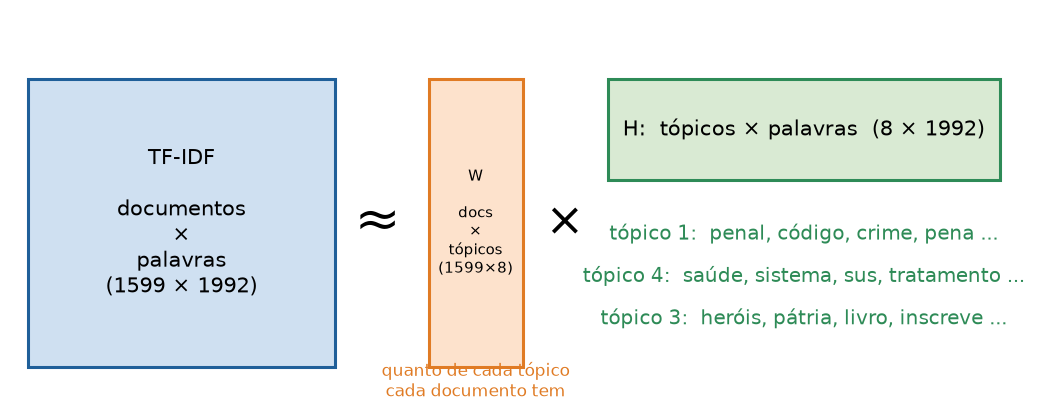

- Cada **tópico** (matriz H) vira uma combinação de palavras.
- Cada **documento** (matriz W) vira uma mistura de tópicos.
- Como todos os números são positivos, os tópicos ficam fáceis de ler, como "partes" que se somam (LEE; SEUNG, 1999).

Diferente do K-means, um documento pode ter um pouco de vários tópicos. Para agrupar, ficamos com o tópico de maior peso.

Para a comparação com o K-means ser justa, começamos com o **mesmo número de grupos: 6**, um para cada tema.

In [ ]:
from sklearn.decomposition import NMF

# n_components=6: 6 tópicos, o mesmo número de grupos do K-means; init="nndsvda": forma de começar que dá resultados estáveis
nmf6 = NMF(n_components=6, init="nndsvda", random_state=42, max_iter=500)
W6 = nmf6.fit_transform(X_tudo)            # W6: quanto de cada tópico cada projeto tem (1599 x 6)
topico6 = W6.argmax(axis=1)                # argmax(axis=1): para cada projeto, o tópico de maior peso

for i, comp in enumerate(nmf6.components_):  # components_ é a matriz H: um tópico por linha, uma palavra por coluna
    print(f"tópico {i} ({(topico6 == i).sum():>3} projetos):", ", ".join(vocab[np.argsort(comp)[::-1][:7]]))

Já é melhor que o K-means: não aparece mais um grupo gigante. Mas leia os tópicos com atenção:

- **Três tópicos são de homenagens**: títulos de "Capital Nacional" (0), "Dia Nacional de…" (2) e Livro dos Heróis da Pátria (3). Para a Câmara é um tema só; para o algoritmo, são três jeitos muito diferentes de escrever.
- Sobraram só 3 tópicos para os outros 5 temas, então **dois pares ficaram juntos**:
  - tópico 1: "código, penal, … trânsito" → **Penal + Trânsito** (os dois falam de "código": Código Penal, Código de Trânsito);
  - tópico 5: "educação, … trabalho" → **Educação + Trabalho**.

O agrupamento encontra a estrutura **mais forte do texto**, e aqui o jeito de escrever as homenagens pesa mais do que a diferença entre Educação e Trabalho. A saída é dar mais espaço: vamos pedir **8 tópicos**.

In [ ]:
# n_components=8: 8 tópicos, 2 a mais que o número de temas, para sobrar espaço depois das homenagens; init="nndsvda": forma de começar que dá resultados estáveis
nmf = NMF(n_components=8, init="nndsvda", random_state=42, max_iter=500)
W = nmf.fit_transform(X_tudo)              # W: quanto de cada tópico cada projeto tem (1599 x 8)
topico = W.argmax(axis=1)                  # argmax(axis=1): para cada projeto, o tópico de maior peso

for i, comp in enumerate(nmf.components_): # components_ é a matriz H: um tópico por linha, uma palavra por coluna
    print(f"tópico {i} ({(topico == i).sum():>3} projetos):", ", ".join(vocab[np.argsort(comp)[::-1][:7]]))

Agora sim: sem nunca ter visto o tema, o NMF encontrou oito tópicos que uma pessoa consegue nomear em segundos: títulos de "Capital Nacional", Penal, datas comemorativas, Livro dos Heróis da Pátria, Saúde (SUS), Educação (Lei de Diretrizes e Bases), Trabalho (CLT) e Trânsito. As homenagens continuam em 3 tópicos, mas Penal se separou de Trânsito e Educação se separou de Trabalho.

Daqui em diante usamos o NMF com 8 tópicos (a variável `topico`).

## 2.5 Como avaliar sem gabarito

No não supervisionado não existe matriz de confusão, porque não existe gabarito. Duas formas de avaliar:

**1. Ler.** Olhar as palavras de cada grupo e alguns exemplos. É a avaliação mais importante, e é humana.

In [ ]:
base["topico"] = topico                                # guarda o tópico de cada projeto na tabela
for i in [0,1,2,3,4,5,6,7]:                                       # vamos ler os 8 tópicos
    print(f"-- exemplos do tópico {i}:")
    # loc[condição, coluna] filtra as ementas desse tópico; sample(5) sorteia 5 delas
    for e in base.loc[base["topico"] == i, "ementa"].sample(5, random_state=7):
        print("  ", e[:130])                           # [:130] mostra só os primeiros 130 caracteres

O tópico 3 é limpíssimo. O tópico 2 é "datas comemorativas", mas lendo os exemplos aparecem intrusos: "Cria o selo…" e "salário profissional **nacional**" entraram pelas palavras "cria" e "nacional". Ler exemplos mostra isso; as palavras do topo, sozinhas, não mostram.

Agora a mesma leitura com o **K-means**, também com 8 grupos, para comparar:

In [ ]:
# os mesmos 8 grupos, agora com o K-means, para comparar a leitura com a do NMF
km8 = KMeans(n_clusters=8, n_init=10, random_state=42).fit(X_tudo)
base["grupo_km"] = km8.labels_                         # guarda o grupo do K-means de cada projeto

for i in range(8):                                     # percorre os 8 grupos
    tamanho = (base["grupo_km"] == i).sum()            # quantos projetos caíram nesse grupo
    palavras = vocab[np.argsort(km8.cluster_centers_[i])[::-1][:6]]   # as 6 palavras de maior valor no centro do grupo
    print(f"-- grupo {i} do K-means ({tamanho} projetos):", ", ".join(palavras))
    # sorteia 5 ementas do grupo; [:130] mostra só os primeiros 130 caracteres
    for e in base.loc[base["grupo_km"] == i, "ementa"].sample(5, random_state=7):
        print("  ", e[:130])

Compare com a leitura do NMF:

- **Os grupos "fáceis" saem limpos nos dois métodos**: Penal, Saúde (SUS), Heróis da Pátria, Capital Nacional e Dia Nacional.
- **O K-means tem um grupo-gaveta com 784 projetos** (o grupo 2), em que cai de tudo: homicídio em série, cultura de paz nas escolas, tráfico de pessoas em aeroportos, Estatuto da Criança, isenção para advogados… Não dá para dar um nome a ele.
- **O grupo 6 mistura Trânsito com Penal**, só porque os dois falam de "código brasileiro" (Código de Trânsito Brasileiro, Código Penal Brasileiro).
- **O grupo 7 mistura profissões com transporte** ("profissão de Escritor" junto com "programas de milhagem").

Ler os exemplos mostra o que a pureza (mais adiante) resume em um número: os grupos do NMF são mais fáceis de nomear.


**2. Só porque desta vez temos gabarito:** podemos espiar como os tópicos se distribuem pelos temas oficiais. É a mesma lógica da matriz de confusão da Parte 1, só que as linhas são grupos sem nome.

In [ ]:
# crosstab conta quantos projetos de cada tópico (linha) caíram em cada tema oficial (coluna)
tabela = pd.crosstab(base["topico"], base["tema_curto"])[ordem_temas]

# pureza: em cada tópico, quantos são do tema mais comum dele (max por linha); soma tudo e divide pelo total
print("Pureza:", round(tabela.max(axis=1).sum() / len(base), 3))

# mapa de calor da tabela: quanto mais escuro, mais projetos
fig, ax = plt.subplots(figsize=(8, 15))
ax.imshow(tabela.values, cmap="Blues")                 # desenha a tabela como imagem colorida
ax.set_xticks(range(len(ordem_temas)))                 # uma marca por tema no eixo horizontal
ax.set_xticklabels(ordem_temas)
ax.set_yticks(range(len(tabela)))                      # uma marca por tópico no eixo vertical
ax.set_yticklabels([f"tópico {i}" for i in tabela.index])
for i in range(tabela.shape[0]):                       # escreve o número dentro de cada quadradinho
    for j in range(tabela.shape[1]):
        ax.text(j, i, tabela.values[i, j], ha="center", va="center",
                color="white" if tabela.values[i, j] > 150 else "black")
ax.set_xlabel("tema oficial (que o NMF não viu)")
ax.set_title("Onde cada tópico do NMF caiu")
plt.show()

A **pureza** mostra que 82,8% dos projetos caíram num tópico dominado pelo próprio tema, **sem o algoritmo saber que tema existia**.

Repare de novo como **Homenagens se dividiu em três tópicos**:
- 0: títulos de "Capital Nacional";
- 2: "Dia Nacional de…";
- 3: Livro dos Heróis da Pátria.

Para a Câmara é um tema só; para o algoritmo, são três jeitos muito diferentes de escrever. O agrupamento encontra a estrutura **mais forte do texto**, que nem sempre coincide com as categorias que a gente queria.

Para fechar, a comparação justa entre os dois métodos, com o **mesmo número de grupos**:


In [ ]:
def pureza(grupos):
    # em cada grupo, quantos projetos são do tema mais comum dele; soma tudo e divide pelo total de projetos
    tabela_grupos = pd.crosstab(grupos, base["tema_curto"])
    return tabela_grupos.max(axis=1).sum() / len(base)

comparacao_grupos = {}
for k in [6, 8]:                                       # 6 grupos (um por tema) e 8 grupos
    rotulos_km = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_tudo)   # grupo de cada projeto no K-means
    rotulos_nmf = NMF(n_components=k, init="nndsvda", random_state=42, max_iter=500).fit_transform(X_tudo).argmax(axis=1)
    comparacao_grupos[f"{k} grupos"] = {
        "K-means: pureza": round(pureza(rotulos_km), 3),
        "K-means: maior grupo": np.bincount(rotulos_km).max(),    # bincount conta quantos projetos há em cada grupo
        "NMF: pureza": round(pureza(rotulos_nmf), 3),
        "NMF: maior grupo": np.bincount(rotulos_nmf).max(),
    }
pd.DataFrame(comparacao_grupos).T                     # .T: uma linha para 6 grupos, outra para 8

- **Com o mesmo número de grupos, o NMF ganha nos dois casos**: 0,665 contra 0,530 com 6 grupos, e 0,828 contra 0,603 com 8.
- O K-means continua com um grupo gigante (877 e 784 projetos); no NMF, o maior grupo é bem menor.
- Passar de 6 para 8 ajuda os dois, porque as homenagens "gastam" 3 grupos sozinhas.

✏️ **Experimente:** troque `n_components=8` por 10 na seção 2.4, rode de novo até aqui e veja se a pureza continua subindo, e se os tópicos novos ainda fazem sentido ao ler as palavras.

## 2.6 De ponta a ponta: usar o agrupamento para criar rótulos

Agora juntamos as duas partes. A situação: uma base sem rótulo, sem orçamento para alguém ler documento por documento.

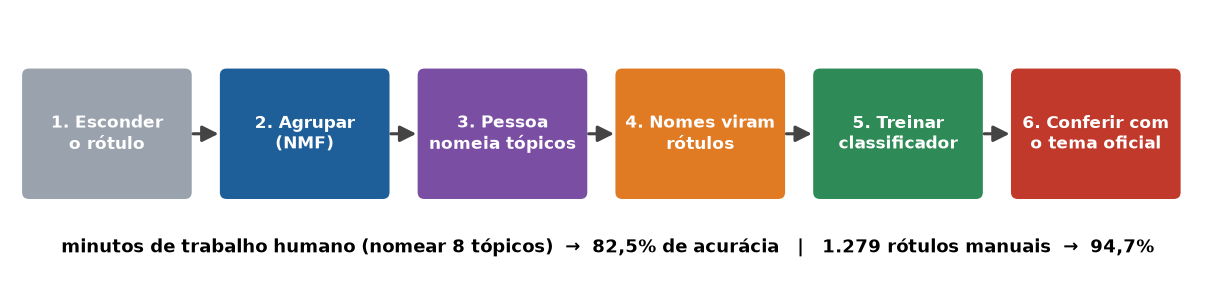

In [ ]:
# 1-2. separa treino e teste e agrupa SÓ o treino (o teste fica guardado para a conferência final)
treino, teste = train_test_split(base, test_size=0.2, random_state=42, stratify=base["tema_curto"])
vet_t = TfidfVectorizer(stop_words=list(palavras_vazias), min_df=2, max_df=0.5)
nmf_t = NMF(n_components=8, init="nndsvda", random_state=42, max_iter=500)
# fit_transform do TF-IDF e depois do NMF; argmax pega o tópico principal de cada projeto de treino
topico_treino = nmf_t.fit_transform(vet_t.fit_transform(treino["texto"])).argmax(axis=1)
vocab_t = np.array(vet_t.get_feature_names_out())

for i, comp in enumerate(nmf_t.components_):          # mostra as palavras de cada tópico para a pessoa ler
    print(f"tópico {i}:", ", ".join(vocab_t[np.argsort(comp)[::-1][:6]]))

**Passo 3 — você é a pessoa que nomeia.** Leia os tópicos acima e preencha o dicionário `nomes` com o tema de cada um.

Na nossa execução a ordem foi a do dicionário abaixo; **se na sua a ordem mudou, corrija os números**.

In [ ]:
from sklearn.svm import LinearSVC     # versão do SVM linear feita para muitos documentos e muitas palavras

# 3. o nome que a pessoa deu a cada tópico, lendo as palavras
nomes = {0: "Homenagens", 1: "Penal", 2: "Homenagens", 3: "Homenagens",
         4: "Saúde", 5: "Educação", 6: "Transporte", 7: "Trabalho"}

# 4. cada projeto de treino recebe o nome do seu tópico como rótulo
treino = treino.copy()                                  # copy() evita mexer na tabela original
treino["rotulo_inventado"] = [nomes[t] for t in topico_treino]
print("Rótulos inventados iguais ao tema oficial:",
      round((treino["rotulo_inventado"] == treino["tema_curto"]).mean(), 3))

# 5. treina um classificador com os rótulos INVENTADOS
modelo_sem_anotacao = Pipeline([("tfidf", TfidfVectorizer()), ("clf", LinearSVC())])
modelo_sem_anotacao.fit(treino["texto"], treino["rotulo_inventado"])

# 6. confere com o tema OFICIAL, no teste que ninguém tocou
p = modelo_sem_anotacao.predict(teste["texto"])
print("Treinado com rótulos inventados -> acurácia no teste:", round(accuracy_score(teste["tema_curto"], p), 4))

# para comparar: o mesmo modelo treinado com os rótulos oficiais
modelo_anotado = Pipeline([("tfidf", TfidfVectorizer()), ("clf", LinearSVC())])
modelo_anotado.fit(treino["texto"], treino["tema_curto"])
print("Treinado com o tema oficial    -> acurácia no teste:",
      round(accuracy_score(teste["tema_curto"], modelo_anotado.predict(teste["texto"])), 4))

# a matriz de confusão da Parte 1, agora com os 6 temas
pd.DataFrame(confusion_matrix(teste["tema_curto"], p, labels=ordem_temas), index=ordem_temas, columns=ordem_temas)

In [ ]:
treino

Como ler esse resultado:

- **82,5% sem ninguém rotular um único documento**, só nomeando 8 tópicos. Com os 1.279 rótulos oficiais, o mesmo modelo chega a 94,7%. A diferença de 12 pontos é o "preço" de não ter anotação; os rótulos inventados foram uma boa largada.
- **O modelo herda os erros dos rótulos.** Leia a matriz como na Parte 1: a linha Educação tem 10 projetos que foram parar na coluna Homenagens. O tópico "Dia Nacional de…" tem intrusos de Saúde, Educação e Trabalho (do mesmo tipo do "Cria o selo Escola Voluntária" da seção 2.5); todos eles receberam o rótulo Homenagens, e o modelo aprendeu isso. Penal e Homenagens, que tinham tópicos limpos, saem quase perfeitos.
- **Na prática**, isso é um ponto de partida: uma pessoa revisa só os documentos em que o modelo tem menos certeza, corrige os rótulos e treina de novo. Muito mais barato do que ler tudo do zero.

## 2.7 Para a próxima sessão

Hoje os rótulos vieram de duas fontes:
- de pessoas (as emoções das frases, o tema oficial dos projetos);
- de grupos (o NMF).

Na Sessão 8 aparece uma terceira ideia: e se **o próprio texto** virasse o rótulo? Esconder uma palavra da frase e pedir para o modelo adivinhá-la não precisa de anotação nenhuma. É assim que se treinam os *word embeddings* e modelos como o BERT.

---
# Exercícios

1. **Matriz de confusão.** Monte a matriz do Gradient Boosting (seção 1.4) e calcule na mão a precisão e o recall de **medo**. Confira com o `classification_report`.
2. **Outro algoritmo na busca.** Troque o `SVC(kernel="linear")` do `GridSearchCV` (seção 1.11) por `SGDClassifier(random_state=42)` e use a grade `{"tfidf__ngram_range": [(1, 1), (1, 2)], "clf__alpha": [0.0001, 0.001, 0.01]}`. O resultado no teste ficou perto do previsto pela validação cruzada?
3. **Limiar.** Na seção 1.12, qual é o menor limiar que mantém a precisão acima de 0,70? Quantas frases ele sinaliza?
4. **Suas frases.** Escreva 5 frases suas (uma de cada emoção e uma com negação) e veja o que o modelo salvo responde. Escolha um erro e explique-o usando a matriz de confusão ou os pesos da seção 1.13.
5. **Desafio — rótulos melhores.** Na seção 2.6, em vez de chamar os tópicos 0, 2 e 3 de "Homenagens", dê nomes diferentes ("Capital Nacional", "Datas", "Heróis") e treine o modelo com 8 rótulos. Depois, antes de comparar com o tema oficial, junte as três previsões de volta em "Homenagens". A acurácia muda? Por quê?

## Para aprofundar

- GÉRON, A. *Mãos à Obra: Aprendizado de Máquina com Scikit-Learn & TensorFlow.* Alta Books, 2019. (Capítulos sobre classificação, métricas de avaliação e aprendizado não supervisionado.)
- LEE, D. D.; SEUNG, H. S. *Learning the parts of objects by non-negative matrix factorization.* Nature, v. 401, p. 788–791, 1999. [nature.com/articles/44565](https://www.nature.com/articles/44565)
- scikit-learn — documentação: [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) · [Tuning the hyper-parameters (GridSearchCV)](https://scikit-learn.org/stable/modules/grid_search.html) · [Clustering (K-means)](https://scikit-learn.org/stable/modules/clustering.html) · [Decomposing signals in components (NMF)](https://scikit-learn.org/stable/modules/decomposition.html) · [Model persistence (joblib)](https://scikit-learn.org/stable/model_persistence.html)
- Câmara dos Deputados — Dados Abertos (proposições e temas): [dadosabertos.camara.leg.br](https://dadosabertos.camara.leg.br/)